# Dissolved oxygen electrode response time

A dissolved oxygen (DO) probe does not respond instantaneously to changes in dissolved oxygen. In a polarographic sensor, an oxygen-permeable membrane is stretched across the very tip of the probe cap, separating the external liquid from an internal electrolyte chamber and the cathode.

Because oxygen is reduced almost instantaneously once it contacts the cathode, the sensor reading is mass-transfer limited: it is governed by how fast dissolved oxygen diffuses from the bulk fluid, across the boundary layer, and through this tip membrane.

Lumping these resistances into a single characteristic time constant ($\tau_E$), the dynamic response is modeled as:

$$\frac{dy}{dt} = \frac{1}{\tau_E}\left(y_f - y\right)$$

where $y(t)$ is the probe reading and $y_f$ corresponds to the dissolved oxygen concentration in the bulk fluid. For an ideal step change from an initial reading $y(0) = y_0$, integration yields:

$$y(t) = y_0 + (y_f - y_0)\left(1 - e^{-t/\tau_E}\right)$$

At $t = \tau_E$, the response reaches $1 - e^{-1} \approx 63.2\%$ of the total step change.

This notebook fits that equation to each trial in your data file and reports $\tau_E$ with a 95% confidence interval, plots each fit against the data, and plots the residuals so you can judge whether the first-order model describes your probe.

The model assumes the step happens at $t = 0$, so the first row of your data should be the moment the probe enters the new vessel. The notebook uses the reading in that row as $y_0$.

**To use it:** put your data file in the same folder as this notebook and set the file name in the settings cell. Then choose **Run → Run All Cells** from the menu. The cells depend on one another, so they must run in order from the top; running only a later cell gives a `NameError`. After changing a setting, run all cells again.

## Sensor specifications

The lab uses Mettler Toledo InPro 6850i polarographic sensors. The sensing tip consists of a replaceable membrane body containing a steel mesh-reinforced PTFE/silicone composite membrane (PTFE facing the sample), backed by a thin layer of electrolyte over the platinum cathode.

The manufacturer rates the probe response at $T_{98} < 90\text{ s}$ at 25 °C for an air-to-nitrogen step. Assuming first-order dynamics:

$$1 - e^{-T_{98}/\tau_E} = 0.98 \implies T_{98} = \tau_E \ln(50) \approx 3.9\,\tau_E$$

This specification corresponds to an expected $\tau_E \le 23\text{ s}$.

Compare your experimentally measured $\tau_E$ with this manufacturer specification:

* $\tau_E \le 23\text{ s}$: Normal probe operation.
* $\tau_E$ substantially above $23\text{ s}$: Indicates insufficient polarization time, fouling or aging of the tip membrane, or inadequate mixing (poor convective mass transfer) around the probe tip.

Section 9 explains what your measured $\tau_E$ means for the $k_La$ values you can measure.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, OptimizeWarning
from scipy.stats import t as t_dist

# Some notebook environments running Matplotlib 3.10 print harmless
# "parameter as float was deprecated" warnings when laying out figures.
warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

## 1. Settings

Change only this cell. The first column of the data file must be time, in seconds, whatever its header says. Every other column holds the probe readings for one trial and can have its own header, such as `Trial 1` or `Run A`. Trials of different lengths are fine: leave the unused cells at the bottom of a shorter trial blank.

In [2]:
DATA_FILE = "Electy1.csv"

# Label for the probe reading on the plots, including its units.
READING_LABEL = "DO reading (% air saturation)"

# Starting guess for the response time (s). Change it only if a fit fails.
TAU_GUESS = 30.0

# Trial shown in the representative figure in Section 7. Type its column header
# exactly, such as "Trial 1". Leave it as "" to use the first trial in the file.
REPRESENTATIVE_TRIAL = ""

# The representative figure is also saved to this file.
FIGURE_FILE = "tauE_representative_figure.png"

## 2. Load the data

In [3]:
if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell "
        "to match its name exactly."
    )
df = pd.read_csv(DATA_FILE)
df = df.dropna(axis="columns", how="all")         # ignore empty columns left over from Excel
TIME_COLUMN = df.columns[0]                         # the first column is always time
trial_columns = list(df.columns[1:])

trials = {}
for trial in trial_columns:
    rows = df[[TIME_COLUMN, trial]].dropna()          # skip blank cells in shorter trials
    trials[trial] = (rows[TIME_COLUMN].to_numpy(dtype=float),
                     rows[trial].to_numpy(dtype=float))
    t_trial = trials[trial][0]
    print(f"{trial}: {len(t_trial)} points from {t_trial.min():g} to {t_trial.max():g} s")

Trial 1: 10 points from 0 to 270 s
Trial 2: 10 points from 0 to 270 s
Trial 3: 10 points from 0 to 270 s


## 3. Model

In [4]:
def first_order(t, y0, yf, tau_E):
    # Probe reading after a step change at t = 0.
    return y0 + (yf - y0) * (1.0 - np.exp(-t / tau_E))

## 4. Fit each trial

For each trial, $y_0$ is set to your first reading, and the fit adjusts $y_f$ and $\tau_E$ until the sum of squared residuals between the model and the readings is as small as possible. The 95% confidence interval for each fitted parameter is calculated the same way as for the slope of a linear fit: the standard error of the parameter multiplied by the critical $t$-value corresponding to your degrees of freedom ($n - p$, where $n$ is the total number of data points and $p$ is the number of fitted parameters).

This interval reflects only how closely one trial's readings scatter around its fitted curve. The spread of $\tau_E$ across replicate trials, calculated in Section 5, is the better measure of how reproducible your probe's response time is.

In [5]:
results = {}
for trial, (t_data, y_data) in trials.items():
    y0 = y_data[0]   # the first reading, taken when the probe enters the new vessel

    def model(t, yf, tau_E):
        return first_order(t, y0, yf, tau_E)

    p0 = [y_data[-1], TAU_GUESS]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", OptimizeWarning)
            popt, pcov = curve_fit(model, t_data, y_data, p0=p0)
    except (RuntimeError, OptimizeWarning, ValueError) as err:
        print(f"{trial}: the fit failed ({err}). Try a different TAU_GUESS.")
        continue

    dof = len(t_data) - len(popt)
    half_width = t_dist.ppf(0.975, dof) * np.sqrt(np.diag(pcov))
    params = np.array([y0, popt[0], popt[1]])
    results[trial] = {"params": params, "ci": np.array([0.0, half_width[0], half_width[1]]),
                      "residuals": y_data - first_order(t_data, *params)}

print("Best-fit values with 95% confidence intervals\n")
for trial, r in results.items():
    (y0, yf, tau_E), (_, ci_yf, ci_tau) = r["params"], r["ci"]
    print(f"{trial}:  tau_E = {tau_E:.1f} ± {ci_tau:.1f} s   "
          f"(y0 = {y0:.1f} from the first reading, yf = {yf:.1f} ± {ci_yf:.1f})")

Best-fit values with 95% confidence intervals

Trial 1:  tau_E = 202.2 ± 68.4 s   (y0 = 0.7 from the first reading, yf = 119.0 ± 24.1)
Trial 2:  tau_E = 208.5 ± 76.6 s   (y0 = 0.7 from the first reading, yf = 121.1 ± 27.1)
Trial 3:  tau_E = 267.6 ± 154.6 s   (y0 = 0.5 from the first reading, yf = 138.6 ± 54.1)


## 5. Response time across replicate trials

If your trials are replicates, meaning repeated steps under the same conditions, this cell averages $\tau_E$ across them and reports a 95% confidence interval from their spread, using the t value for the number of trials minus one. This is the same calculation as Excel's `CONFIDENCE.T`. 

In [6]:
tau_values = np.array([r["params"][2] for r in results.values()])
n = len(tau_values)
if n >= 2:
    mean_tau = tau_values.mean()
    sd_tau = tau_values.std(ddof=1)
    ci_tau = t_dist.ppf(0.975, n - 1) * sd_tau / np.sqrt(n)
    print(f"{n} trials: mean tau_E = {mean_tau:.1f} s, standard deviation = {sd_tau:.1f} s")
    print(f"95% confidence interval on the mean: {mean_tau:.1f} ± {ci_tau:.1f} s")
else:
    print("At least two successful fits are needed to compare replicate trials.")

3 trials: mean tau_E = 226.1 s, standard deviation = 36.1 s
95% confidence interval on the mean: 226.1 ± 89.6 s


## 6. Model and data

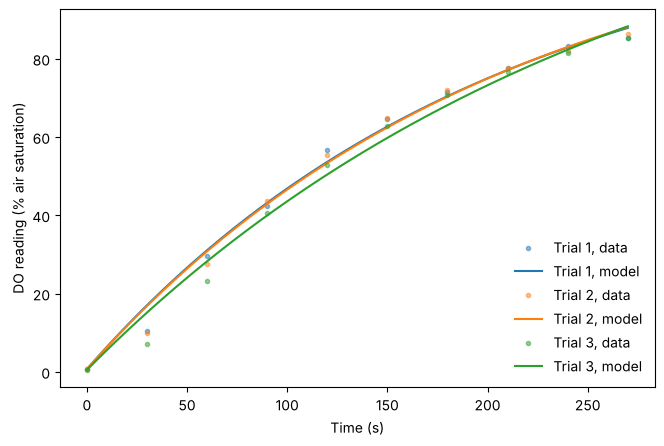

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (trial, r) in enumerate(results.items()):
    t_data, y_data = trials[trial]
    color = f"C{i}"
    t_smooth = np.linspace(0.0, t_data.max(), 300)
    ax.plot(t_data, y_data, "o", markersize=3, alpha=0.5, color=color, label=f"{trial}, data")
    ax.plot(t_smooth, first_order(t_smooth, *r["params"]), "-", color=color, label=f"{trial}, model")

ax.set_xlabel("Time (s)")
ax.set_ylabel(READING_LABEL)
ax.legend(frameon=False, loc="lower right")
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.12, top=0.96)
plt.show()

## 7. Representative figure

This is a representative figure showing one trial, with the readings shown as symbols and the fitted model as a line. Choose the trial in the settings cell with `REPRESENTATIVE_TRIAL`. The figure has no title because the caption you write in your report takes its place; state $\tau_E$ in that caption. The figure is saved at print resolution to the file named in `FIGURE_FILE`, in the same folder as this notebook.

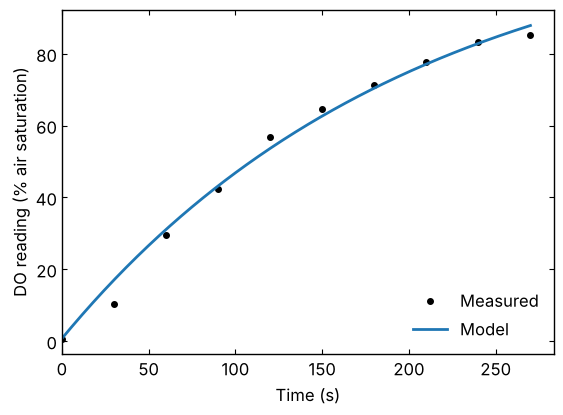

Trial 1: tau_E = 202.2 ± 68.4 s
Figure saved to tauE_representative_figure.png.


In [8]:
if REPRESENTATIVE_TRIAL == "":
    rep_trial = next(iter(results))
elif REPRESENTATIVE_TRIAL in results:
    rep_trial = REPRESENTATIVE_TRIAL
else:
    raise ValueError(
        f'"{REPRESENTATIVE_TRIAL}" is not one of the fitted trials. '
        f"Set REPRESENTATIVE_TRIAL to one of: {', '.join(results)}."
    )

r = results[rep_trial]
t_data, y_data = trials[rep_trial]
t_smooth = np.linspace(0.0, t_data.max(), 300)

with plt.rc_context({"font.size": 12, "axes.linewidth": 1.0}):
    fig, ax = plt.subplots(figsize=(6.0, 4.2))
    ax.plot(t_data, y_data, "o", markersize=4, color="black", label="Measured")
    ax.plot(t_smooth, first_order(t_smooth, *r["params"]), "-", color="C0",
            linewidth=2, label="Model")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(READING_LABEL)
    ax.set_xlim(left=0)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower right")
    fig.subplots_adjust(left=0.14, right=0.96, bottom=0.14, top=0.96)
    fig.savefig(FIGURE_FILE, dpi=300)
    plt.show()

print(f"{rep_trial}: tau_E = {r['params'][2]:.1f} ± {r['ci'][2]:.1f} s")
print(f"Figure saved to {FIGURE_FILE}.")

## 8. Residuals

A residual is the measured reading minus the model's prediction at the same time. The first residual is always zero, because $y_0$ is your first reading. If the first-order model describes your probe, the rest are small and scatter randomly above and below zero.

A pattern means the model is missing something. Negative residuals over the first few points mean the reading started rising more slowly than a first-order curve allows, and the fit usually offsets them with positive residuals later in the run. A slow start can come from diffusion through the membrane, poor mixing in the receiving vessel, or starting the clock before the probe was in the new solution. Residuals that keep drifting after the reading has leveled off point to drift in the probe, and a single residual that jumps and returns marks an event such as a bubble on the membrane. All panels share the same vertical scale, so you can see whether a pattern appears in every trial or only one.

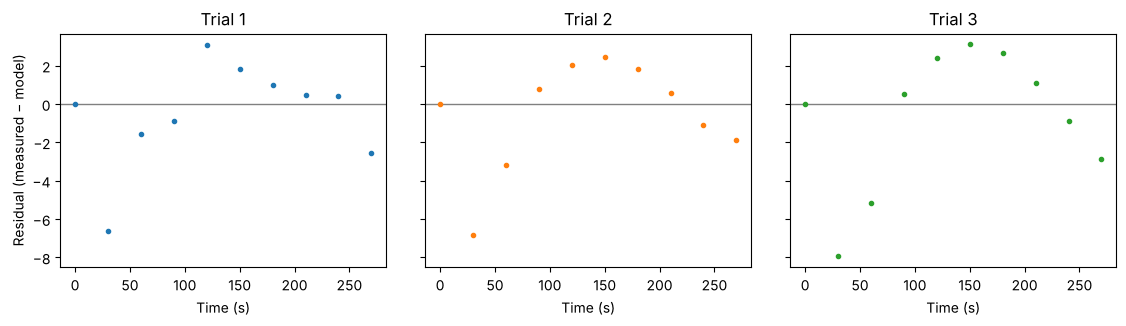

In [9]:
n_trials = len(results)
n_cols = min(n_trials, 3)
n_rows = int(np.ceil(n_trials / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows),
                         sharey=True, squeeze=False)

for ax, (i, (trial, r)) in zip(axes.flat, enumerate(results.items())):
    t_data = trials[trial][0]
    ax.axhline(0.0, color="gray", linewidth=1)
    ax.plot(t_data, r["residuals"], "o", markersize=3, color=f"C{i}")
    ax.set_title(trial)
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Residual (measured − model)")
for ax in list(axes.flat)[n_trials:]:
    ax.set_visible(False)

fig.subplots_adjust(left=0.1, right=0.98, bottom=0.17 if n_rows == 1 else 0.1,
                    top=0.9 if n_rows == 1 else 0.94, wspace=0.12, hspace=0.45)
plt.show()

## 9. Why a slow probe affects your $k_La$

In Week 1, you estimated $k_La$ from how fast the dissolved oxygen reading rose after the air was turned on. That reading reflects two processes in series: the liquid fills with oxygen on a time scale of $1/k_La$, and the probe responds on a time scale of $\tau_E$. If the probe is fast, the reading follows the liquid and your $k_La$ is correct. If it is slow, the reading lags behind, the curve rises too gradually, and you underestimate $k_La$.

The probe is fast enough when $\tau_E < 1/(5\,k_La)$. In that case, the $k_La$ you calculate is no more than about 2% below the true value. As $\tau_E$ gets larger the error grows quickly: your $k_La$ is about 13% too low when $\tau_E = 1/(2\,k_La)$ and about 33% when $\tau_E = 1/k_La$. Rearranging the criterion gives the largest $k_La$ your probe can measure accurately:

$$k_La^{\max} = \frac{1}{5\,\tau_E}$$

In [10]:
# Largest kLa this probe can measure: tau_E < 1/(5 kLa), so kLa_max = 1/(5 tau_E)
if len(tau_values) == 0:
    print("No successful fits, so kLa_max cannot be calculated.")
else:
    tau_for_limit = tau_values.mean()
    kla_max = 1.0 / (5.0 * tau_for_limit)
    print(f"Mean tau_E = {tau_for_limit:.1f} s from {len(tau_values)} trial(s)")
    print(f"kLa_max = 1/(5 tau_E) = {kla_max:.4f} 1/s = {kla_max * 3600:.1f} 1/h")
    print("kLa values below this limit are underestimated by less than about 2%.")

Mean tau_E = 226.1 s from 3 trial(s)
kLa_max = 1/(5 tau_E) = 0.0009 1/s = 3.2 1/h
kLa values below this limit are underestimated by less than about 2%.
